# LSTM on BPIC 2012 with Synthetic Signature Fraud — comparative baseline

Comparative-study copy of `main_gine_bpic2012.ipynb`. The data processing, surrogate-transaction cut positions, labels/fraud rate,  nested CV, cut-only training, threshold selection and plots are **identical** — only the model is swapped (GINE → LSTM). It consumes the same per-session PyG `Data` objects and reads them as sequences (the graph structure is ignored).

> **Fraud definition (escalating signature).** Each fraud trace carries a back-loop motif (A_ACCEPTED+COMPLETE → A_PARTLYSUBMITTED+COMPLETE → A_ACCEPTED+COMPLETE) injected into the pre-`O_ACCEPTED` prefix with a probability that **escalates toward the transaction** — the takeover ramps up as it nears the money movement. Suspicious evidence therefore **builds up** as the session unfolds: detection **rises** with the observed prefix until ~the transaction, then flattens (the signal-free suffix dilutes it) — see Section 7. A fraction of legit traces carry the same pattern (**class overlap**), capping peak detectability so the task stays non-trivial. (Random-Nolle anomalies were unlearnable by these supervised classifiers; a positive-control check confirmed the pipeline is correct.)

## 1. Imports & constants

In [20]:
# --- ensure repo root is the working directory (notebook may be launched from notebooks/) ---
import os as _os
from pathlib import Path as _Path
_root = _Path.cwd()
while not (_root / 'pyproject.toml').exists() and _root != _root.parent:
    _root = _root.parent
_os.chdir(_root)

import os
import json
import math
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    confusion_matrix, precision_recall_curve, average_precision_score,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_mean_pool, global_max_pool

CUT_LEVEL = 1
DELTA_BINS = [0.03, 0.22, 1.11, 10]
DELTA_LABELS = ['INSTANT', 'FAST', 'MEDIUM', 'SLOW']

## 2. Experiment configuration

In [21]:
# ---- BPIC 2012 experiment configuration ----
COL_CASE, COL_EVENT, COL_TIME = 'case_id', 'activity', 'timestamp'
SURROGATE_ACTIVITY = 'O_ACCEPTED+COMPLETE'   # late commitment activity used as the surrogate "transaction"
CUT_LEVEL = 1
DATA_PATH = 'data/processed/bpic_2012_signature.parquet' 

## 3. Function library

Data/graph/training/eval helpers identical to the GINE notebook; the model is **LSTMFraudModel** and the evaluator constructs it instead of GINE.

In [22]:
def compute_time_deltas(df):
    """Per-session list of (activity, delta_seconds); first event delta = 0 (BPIC columns via COL_* globals)."""
    session_deltas = {}
    for sid, group in df.groupby(COL_CASE):
        group = group.sort_values(COL_TIME)
        times = group[COL_TIME].tolist()
        labels = group[COL_EVENT].tolist()
        deltas = [0]
        for i in range(1, len(times)):
            deltas.append((times[i] - times[i - 1]).total_seconds())
        session_deltas[sid] = list(zip(labels, deltas))
    return session_deltas

In [23]:
def discretise_delta(delta: float):
    for th, label in zip(DELTA_BINS, DELTA_LABELS):
        if delta <= th:
            return label
    return DELTA_LABELS[-1]

In [24]:
def session_to_nx_original(session_id: str, session_deltas: dict, label_to_int: dict):
    """Build a directed graph for a session from the original sequence."""
    raw_seq_deltas = session_deltas[session_id]
    events = [event for event, _ in raw_seq_deltas]
    deltas = [delta for _, delta in raw_seq_deltas]

    edge_deltas = defaultdict(list)
    for i, (a, b) in enumerate(zip(events, events[1:])):
        if a not in label_to_int or b not in label_to_int:
            continue
        a_int = label_to_int[a]
        b_int = label_to_int[b]
        delta = deltas[i + 1] if i + 1 < len(deltas) else 0
        edge_deltas[(a_int, b_int)].append(delta)

    G = nx.DiGraph()
    for (a_int, b_int), delta_list in edge_deltas.items():
        mean_delta = float(np.mean(delta_list))
        G.add_edge(a_int, b_int, weight=len(delta_list), delta_bin=discretise_delta(mean_delta))
    return G

In [25]:
def compute_cut_positions(session_deltas, surrogate_activity):
    """Surrogate-transaction cut positions: index of the 1st/2nd/3rd occurrence of the surrogate
    activity, so session_deltas[sid][:pos] is everything before it (replaces RDP transaction logic)."""
    cuts = {}
    for sid, seq in session_deltas.items():
        events = [e for e, _ in seq]
        positions = [i for i, e in enumerate(events) if e == surrogate_activity]
        d = {}
        for n, p in enumerate(positions[:3], start=1):
            if p > 0:
                d[n] = p
        cuts[sid] = d
    return cuts

In [26]:
def build_augmented_training_graphs(valid_ids, session_deltas, all_cut_positions, labels, label_to_int, wl_iterations, cut_level):
    """Build augmented training graphs: complete sessions + cut sessions side by side."""
    graphs_augmented = []
    labels_augmented = []
    source_ids = []
    is_cut = []

    for sid in valid_ids:
        temp_deltas = {sid: session_deltas[sid]}
        G_complete = session_to_nx_original(sid, temp_deltas, label_to_int)

        if G_complete.number_of_edges() > 0:
            graphs_augmented.append(G_complete)
            labels_augmented.append(labels[sid])
            source_ids.append(sid)
            is_cut.append(False)

        if cut_level not in all_cut_positions[sid]:
            continue

        cut_position = all_cut_positions[sid][cut_level]
        cut_deltas = session_deltas[sid][:cut_position]
        if len(cut_deltas) < 2:
            continue

        G_cut = session_to_nx_original(sid, {sid: cut_deltas}, label_to_int)
        if G_cut.number_of_edges() == 0:
            continue

        graphs_augmented.append(G_cut)
        labels_augmented.append(labels[sid])
        source_ids.append(sid)
        is_cut.append(True)

    print(f"Total graphs after augmentation: {len(graphs_augmented)}")
    print(f"Complete sessions: {sum(1 for c in is_cut if not c)}")
    print(f"Cut sessions: {sum(1 for c in is_cut if c)}")
    print(f"Fraud graphs: {sum(1 for l in labels_augmented if l == 'fraud')}")
    print(f"Normal graphs: {sum(1 for l in labels_augmented if l == 'normal')}")

    return graphs_augmented, labels_augmented, source_ids, is_cut

In [27]:
def get_graphs(cut_level, valid_ids, all_cut_positions, session_deltas, label_to_int, wl_iterations, cut_graph):
    graphs = []
    labels = []

    for sid in valid_ids:
        if cut_graph:
            if cut_level not in all_cut_positions[sid]:
                continue
            cut_position = all_cut_positions[sid][cut_level]
            cut_deltas = session_deltas[sid][:cut_position]
            if len(cut_deltas) < 2:
                continue
            temp_deltas = {sid: cut_deltas}
        else:
            temp_deltas = {sid: session_deltas[sid]}

        G = session_to_nx_original(sid, temp_deltas, label_to_int)
        if G.number_of_edges() == 0:
            continue

        graphs.append(G)
        labels.append(ses_label[sid])

    return graphs, labels

In [28]:
def compute_fraud_lift_map(cut_level, training_session_ids, training_label, session_deltas, all_cut_positions):
    """Compute fraud lift per transition: fraction_in_fraud - fraction_in_normal, in ~[-1, 1]."""
    fraud_transitions_per_session = []
    normal_transitions_per_session = []

    for sid, label in zip(training_session_ids, training_label):
        cut_position = all_cut_positions[sid].get(cut_level)
        raw = session_deltas[sid]
        if cut_position is not None:
            raw = raw[:cut_position]

        transitions_in_session = set()
        for i in range(1, len(raw)):
            transitions_in_session.add((raw[i - 1][0], raw[i][0]))

        if label == 'fraud':
            fraud_transitions_per_session.append(transitions_in_session)
        else:
            normal_transitions_per_session.append(transitions_in_session)

    n_fraud = len(fraud_transitions_per_session)
    n_normal = len(normal_transitions_per_session)
    if n_fraud == 0 or n_normal == 0:
        return {}

    all_transitions = set()
    for s in fraud_transitions_per_session:
        all_transitions.update(s)
    for s in normal_transitions_per_session:
        all_transitions.update(s)

    fraud_lift_map = {}
    for transition in all_transitions:
        fraud_count = sum(1 for s in fraud_transitions_per_session if transition in s)
        normal_count = sum(1 for s in normal_transitions_per_session if transition in s)
        fraud_lift_map[transition] = fraud_count / n_fraud - normal_count / n_normal

    return fraud_lift_map

In [29]:
def compute_node_features(graph, sequence, sid, active_feature_columns, logs_grouped, imputation_values):
    """Compute per-node scalar features for a per-log graph.

    Returns empty dict when active_feature_columns is empty; the model then runs
    on event embeddings + edge features only.
    """
    if len(active_feature_columns) == 0:
        return {}

    cumulative_times = []
    std_dts_so_far = []
    unique_events_so_far = []
    event_frequency_rank = []
    repeat_indicator = []
    recent_vs_global_dt_ratio = []
    recent_new_event_rate = []
    dt_zscore_so_far = []
    idle_count_so_far = []
    fraction_fast_transitions = []
    event_entropy_so_far = []
    events_since_last_new_event = []

    idle_pause_seconds = 30
    fast_transition_seconds = 0.5
    recent_window_size = 5

    if "cumulative_time" in active_feature_columns:
        running_sum = 0
        for _, dt in sequence:
            running_sum += float(dt)
            cumulative_times.append(running_sum)

    if "std_dt_so_far" in active_feature_columns:
        deltas_seen = []
        for _, dt in sequence:
            deltas_seen.append(float(dt))
            std_dts_so_far.append(0 if len(deltas_seen) < 2 else float(np.std(deltas_seen)))

    if "unique_events_so_far" in active_feature_columns:
        events_seen = set()
        for event_name, _ in sequence:
            events_seen.add(event_name)
            unique_events_so_far.append(len(events_seen))

    if "event_frequency_rank" in active_feature_columns:
        event_counts = {}
        for event_name, _ in sequence:
            event_counts[event_name] = event_counts.get(event_name, 0) + 1
            sorted_events = sorted(event_counts.items(), key=lambda x: (-x[1], x[0]))
            current_event_rank = next(rank for rank, (name, _) in enumerate(sorted_events, start=1) if name == event_name)
            event_frequency_rank.append(float(current_event_rank))

    if "repeat_indicator" in active_feature_columns:
        seen_events = set()
        for event_name, _ in sequence:
            repeat_indicator.append(1 if event_name in seen_events else 0)
            seen_events.add(event_name)

    if "recent_vs_global_dt_ratio" in active_feature_columns:
        deltas = [float(dt) for _, dt in sequence]
        for i in range(len(sequence)):
            recent_window = deltas[max(0, i - recent_window_size + 1):i + 1]
            global_window = deltas[:i+1]
            mean_recent = float(np.mean(recent_window)) if recent_window else 0
            mean_global = float(np.mean(global_window)) if global_window else 1
            recent_vs_global_dt_ratio.append(mean_recent / max(mean_global, 1e-6))

    if "recent_new_event_rate" in active_feature_columns:
        events_seen_so_far = set()
        was_first_time = []
        for event_name, _ in sequence:
            was_first_time.append(event_name not in events_seen_so_far)
            events_seen_so_far.add(event_name)
        for i in range(len(sequence)):
            recent_window = was_first_time[max(0, i - recent_window_size + 1):i+1]
            recent_new_event_rate.append(sum(recent_window) / len(recent_window) if recent_window else 0)

    if "dt_zscore_so_far" in active_feature_columns:
        deltas = [float(dt) for _, dt in sequence]
        for i in range(len(sequence)):
            history = deltas[:i+1]
            if len(history) < 2:
                dt_zscore_so_far.append(0)
            else:
                mean_h, std_h = float(np.mean(history)), float(np.std(history))
                dt_zscore_so_far.append(0 if std_h < 1e-6 else (deltas[i] - mean_h) / std_h)

    if "idle_count_so_far" in active_feature_columns:
        count = 0
        for _, dt in sequence:
            if float(dt) > idle_pause_seconds:
                count += 1
            idle_count_so_far.append(count)

    if "fraction_fast_transitions" in active_feature_columns:
        fast_count = 0
        for i, (_, dt) in enumerate(sequence):
            if float(dt) < fast_transition_seconds:
                fast_count += 1
            fraction_fast_transitions.append(fast_count / (i + 1))

    if "event_entropy_so_far" in active_feature_columns:
        event_counts = {}
        for event_name, _ in sequence:
            event_counts[event_name] = event_counts.get(event_name, 0) + 1
            total = sum(event_counts.values())
            entropy = -sum((c / total) * math.log1p(c / total) for c in event_counts.values())
            event_entropy_so_far.append(entropy)

    if "events_since_last_new_event" in active_feature_columns:
        seen = set()
        steps_since_new = 0
        for event_name, _ in sequence:
            if event_name not in seen:
                seen.add(event_name)
                steps_since_new = 0
            else:
                steps_since_new += 1
            events_since_last_new_event.append(float(steps_since_new))

    synthetic_features = {
        "cumulative_time", "std_dt_so_far", "unique_events_so_far",
        "event_frequency_rank", "repeat_indicator",
        "recent_vs_global_dt_ratio", "recent_new_event_rate", "dt_zscore_so_far",
        "idle_count_so_far", "fraction_fast_transitions", "event_entropy_so_far",
        "events_since_last_new_event",
    }
    df_features = [col for col in active_feature_columns if col not in synthetic_features]

    session_rows = None
    if df_features and logs_grouped is not None:
        session_rows = logs_grouped.get_group(sid).reset_index(drop=True)

    features = {}
    for node in graph.nodes():
        per_node_features = {}
        for col in active_feature_columns:
            if col == 'cumulative_time':
                per_node_features[col] = math.log1p(cumulative_times[node]) if node < len(cumulative_times) else 0
            elif col == 'std_dt_so_far':
                per_node_features[col] = math.log1p(std_dts_so_far[node]) if node < len(std_dts_so_far) else 0
            elif col == 'unique_events_so_far':
                per_node_features[col] = math.log1p(unique_events_so_far[node]) if node < len(unique_events_so_far) else 0
            elif col == "event_frequency_rank":
                per_node_features[col] = event_frequency_rank[node] if node < len(event_frequency_rank) else 0
            elif col == 'repeat_indicator':
                per_node_features[col] = repeat_indicator[node] if node < len(repeat_indicator) else 0
            elif col == "recent_vs_global_dt_ratio":
                per_node_features[col] = math.log1p(recent_vs_global_dt_ratio[node]) if node < len(recent_vs_global_dt_ratio) else 0
            elif col == "recent_new_event_rate":
                per_node_features[col] = recent_new_event_rate[node] if node < len(recent_new_event_rate) else 0
            elif col == "dt_zscore_so_far":
                per_node_features[col] = dt_zscore_so_far[node] if node < len(dt_zscore_so_far) else 0
            elif col == "idle_count_so_far":
                per_node_features[col] = math.log1p(idle_count_so_far[node]) if node < len(idle_count_so_far) else 0
            elif col == "fraction_fast_transitions":
                per_node_features[col] = fraction_fast_transitions[node] if node < len(fraction_fast_transitions) else 0
            elif col == "event_entropy_so_far":
                per_node_features[col] = event_entropy_so_far[node] if node < len(event_entropy_so_far) else 0
            elif col == "events_since_last_new_event":
                per_node_features[col] = math.log1p(events_since_last_new_event[node]) if node < len(events_since_last_new_event) else 0
            else:
                if session_rows is None or node >= len(session_rows):
                    per_node_features[col] = imputation_values.get(col, 0)
                    continue
                value = session_rows.iloc[node][col]
                per_node_features[col] = imputation_values.get(col, 0) if pd.isna(value) else float(value)
        features[node] = per_node_features

    return features

In [30]:
def build_session_graph(sid, session_deltas, cut_position=None, reverse_edges: bool = False):
    """Build a per-log-occurrence graph. One node per log entry, edges carry time deltas."""
    raw = session_deltas[sid]
    if cut_position is not None:
        raw = raw[:cut_position]

    G = nx.DiGraph()
    for i in range(len(raw) - 1):
        G.add_node(i, log_index=i)

    for i in range(len(raw) - 1):
        delta = float(raw[i + 1][1])
        G.add_edge(i, i + 1, mean_dt=delta)
        if reverse_edges:
            G.add_edge(i + 1, i, mean_dt=delta)
    return G, raw

In [31]:
def session_to_pyg_data(sid, session_deltas, cut_position, label, label_to_int, active_feature_columns,
                        logs_grouped=None, imputation_values=None, fraud_lift_map=None, reverse_edges: bool = False):
    """Convert a session into a torch_geometric.data.Data object."""
    G, raw = build_session_graph(sid, session_deltas, cut_position, reverse_edges)
    if G.number_of_edges() == 0:
        return None

    nodes = sorted(G.nodes())
    node_idx = {n: i for i, n in enumerate(nodes)}
    event_ids = [label_to_int.get(raw[n][0], 0) for n in nodes]

    feat_dict = compute_node_features(G, raw, sid, active_feature_columns, logs_grouped, imputation_values)
    if feat_dict:
        feature_names = list(next(iter(feat_dict.values())).keys())
        scalar_feats = np.array([[feat_dict[n][k] for k in feature_names] for n in nodes], dtype=np.float32)
    else:
        scalar_feats = np.zeros((len(nodes), 0), dtype=np.float32)

    edge_index_list = []
    edge_feats_list = []
    for u, v, d in G.edges(data=True):
        edge_index_list.append([node_idx[u], node_idx[v]])
        log_dt = math.log1p(d.get("mean_dt", 0))
        if fraud_lift_map is not None:
            fraud_lift = fraud_lift_map.get((raw[u][0], raw[v][0]), 0)
            edge_feats_list.append([log_dt, fraud_lift])
        else:
            edge_feats_list.append([log_dt])

    edge_index = torch.tensor(edge_index_list, dtype=torch.long).t().contiguous()
    edge_attr = torch.tensor(edge_feats_list, dtype=torch.float32)

    return Data(
        event_ids=torch.tensor(event_ids, dtype=torch.long),
        x_scalar=torch.tensor(scalar_feats, dtype=torch.float32),
        edge_index=edge_index,
        edge_attr=edge_attr,
        y=torch.tensor([label], dtype=torch.float32),
        sid=sid,
        num_nodes=len(nodes),
    )

### LSTM model (verbatim from the baseline file)

In [32]:
class LSTMFraudModel(nn.Module): 
    """ LSTM baseline
 
        Same input as GINEFRaudModl, but hadnels the data differently, the grraph structure is ignored.
    """
 
    def __init__(self, n_event_types : int, n_scalar_node_features : int, event_emb_dim: int = 16, hidden_dim: int = 64, n_layers : int = 2, dropout : float = 0.3, bidirectional = False): 
                
        super().__init__()#calls the constructor of the parent class (nn.Module)
        
        self.event_emb = nn.Embedding(n_event_types, event_emb_dim)
 
        token_input_dim = event_emb_dim + n_scalar_node_features
        self.lstm = nn.LSTM(token_input_dim, hidden_dim, num_layers  = n_layers, dropout = dropout if n_layers > 1 else 0, batch_first = True, bidirectional = bidirectional)
        head_input_dim = hidden_dim * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.Linear(head_input_dim, hidden_dim), 
            nn.ReLU(), 
            nn.Dropout(dropout), 
            nn.Linear(hidden_dim, 1),
        )
    
    def forward(self, batch): 
        # Look up event embeddings, clamp ids to embedding range
        ev_ids = batch.event_ids.clamp(max=self.event_emb.num_embeddings-1) # set a max range and min not set here
        ev_emb = self.event_emb(ev_ids)
 
        if batch.x_scalar.shape[-1] > 0: 
            x = torch.cat([ev_emb, batch.x_scalar], dim =-1)
        else: 
            x = ev_emb
        #Reshape form flat (total_nodes, dim) to padded (batc_size, max_len, dim) using batch.batch to identify which session each node belongs to
        batch_size = int(batch.batch.max().item()) + 1
        sessions = []
        lengths = []
        for session_id in range(batch_size): 
            session_mask = batch.batch == session_id
            session_tokens = x[session_mask]
            sessions.append(session_tokens)
            lengths.append(session_tokens.size(0))
 
        max_len = max(lengths)
        padded = torch.zeros(batch_size, max_len, x.size(-1), device = x.device, dtype = x.dtype)
        for i, session_tokens in enumerate(sessions): 
            padded[i, :lengths[i]] = session_tokens
        
        # pack for LSTM efficiency (skips padding in computation)
        packed = nn.utils.rnn.pack_padded_sequence(padded, lengths, batch_first = True, enforce_sorted = False)
        _, (hidden, _) = self.lstm(packed)
 
        # for bidirectional lstm, concatenate forward and backward final states
        if self.lstm.bidirectional: 
            # hidden shape : (num_layers * 2, batch, hidden_dim)
            # take last layers forward and backward states 
            final = torch.cat([hidden[-2], hidden[-1]], dim = -1)
        else: 
            final = hidden[-1]
        return self.head(final).squeeze(-1)

In [33]:
def _train_one_epoch(model, loader, optimizer, pos_weight, device):
    model.train()
    losses = []
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch)
        loss = F.binary_cross_entropy_with_logits(logits, batch.y.view(-1), pos_weight=pos_weight.to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)
        optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses)) if losses else 0


@torch.no_grad()
def _predict_proba(model, loader, device):
    model.eval()
    probs = []
    for batch in loader:
        batch = batch.to(device)
        probs.append(torch.sigmoid(model(batch)).cpu().numpy())
    return np.concatenate(probs) if probs else np.array([])

In [34]:
def build_fold_data(indices, cut_level, sids, labels, is_cut_list, session_deltas, all_cut_positions,
                    label_to_int, active_feature_columns, logs_grouped, imputation_values, fraud_lift_map, reverse_edges):
    """Build PyG Data objects for a subset of the training pool."""
    fold_data = []
    for i in indices:
        sid = sids[i]
        lab = labels[i]
        cp = all_cut_positions[sid].get(cut_level) if is_cut_list[i] else None
        d = session_to_pyg_data(sid, session_deltas, cp, 1 if lab == 'fraud' else 0, label_to_int,
                                active_feature_columns, logs_grouped, imputation_values,
                                fraud_lift_map=fraud_lift_map, reverse_edges=reverse_edges)
        if d is not None:
            fold_data.append(d)
    return fold_data


def build_fold_test_data(test_indices, cut_level, test_sids_list, test_labels_list, session_deltas, all_cut_positions,
                         label_to_int, active_feature_columns, logs_grouped, imputation_values, fraud_lift_map, reverse_edges):
    """Build PyG data objects for held-out test sessions in a fold."""
    fold_data = []
    for global_idx in test_indices:
        sid = test_sids_list[global_idx]
        cp = all_cut_positions[sid].get(cut_level)
        d = session_to_pyg_data(sid, session_deltas, cp, test_labels_list[global_idx], label_to_int,
                                active_feature_columns, logs_grouped, imputation_values,
                                fraud_lift_map=fraud_lift_map, reverse_edges=reverse_edges)
        if d is not None:
            fold_data.append(d)
    return fold_data

### Nested-CV evaluator (model-agnostic; with precision/recall/F1-vs-threshold plot)

In [35]:
def evaluate_nested(source_ids, labels_augmented, is_cut, session_deltas, all_cut_positions,
                    label_to_int, active_feature_columns=None, logs_grouped=None, imputation_values=None,
                    use_fraud_lift=False, n_splits=5, n_inner_splits=4, n_seeds=3, n_epochs=100,
                    patience=15, lr=1e-3, weight_decay=1e-2, batch_size=32, hidden_dim=32, n_layers=4,
                    dropout=0.5, event_emb_dim=16, device=None, cut_only_training=False,
                    reverse_edges=False, cut_level=1):
    """ nested cross-validation (model-agnostic; identical to the GINE notebook's harness).

    Per OUTER fold the held-out group is used ONLY for out-of-fold metrics. An INNER group-split of the
    remaining data provides the validation set used for early stopping AND threshold selection. So
    train / val / test are disjoint and grouped by session, and the test fold drives no selection.
    """
    if active_feature_columns is None:
        active_feature_columns = []
    if imputation_values is None:
        imputation_values = {}
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    device = torch.device(device)

    n_event_types = max(label_to_int.values()) + 2
    n_edge_features = 2 if use_fraud_lift else 1

    eligible = [i for i, (sid, lab, cf) in enumerate(zip(source_ids, labels_augmented, is_cut))
                if not (cut_only_training and not cf)]
    sids = [source_ids[i] for i in eligible]
    labs = [labels_augmented[i] for i in eligible]
    iscut = [is_cut[i] for i in eligible]
    y = np.array([1 if l == 'fraud' else 0 for l in labs])
    sids_arr = np.array(sids)

    oof_true, oof_prob, oof_pred = [], [], []
    fold_thresholds = []

    outer = StratifiedGroupKFold(n_splits=n_splits)
    print('Start nested cross-validation')
    for fold, (tr_idx, te_idx) in enumerate(outer.split(sids, y, groups=sids_arr)):
        inner = StratifiedGroupKFold(n_splits=n_inner_splits)
        rel_tr, rel_val = next(inner.split(tr_idx, y[tr_idx], groups=sids_arr[tr_idx]))
        in_tr, in_val = tr_idx[rel_tr], tr_idx[rel_val]

        flm = None
        if use_fraud_lift:
            flm = compute_fraud_lift_map(cut_level, [sids[i] for i in in_tr], [labs[i] for i in in_tr],
                                         session_deltas, all_cut_positions)

        def _build(ix):
            return build_fold_data(ix, cut_level, sids, labs, iscut, session_deltas, all_cut_positions,
                                   label_to_int, active_feature_columns, logs_grouped, imputation_values,
                                   flm, reverse_edges)
        train_data, val_data, test_data = _build(in_tr), _build(in_val), _build(te_idx)
        if not train_data or not val_data or not test_data:
            print(f'Fold {fold + 1}/{n_splits}: skipped (empty data)'); continue

        y_val = np.array([int(d.y.item()) for d in val_data])
        y_te = np.array([int(d.y.item()) for d in test_data])
        if len(set(y_val)) < 2 or len(set(y_te)) < 2:
            print(f'Fold {fold + 1}/{n_splits}: skipped (single-class val/test)'); continue

        n_pos = int(sum(1 for d in train_data if d.y.item() == 1))
        n_neg = len(train_data) - n_pos
        pos_weight = torch.tensor([max(n_neg, 1) / max(n_pos, 1)], dtype=torch.float32)
        n_scalar = train_data[0].x_scalar.shape[-1]

        tl = DataLoader(train_data, batch_size=batch_size, shuffle=True)
        vl = DataLoader(val_data, batch_size=batch_size, shuffle=False)
        tel = DataLoader(test_data, batch_size=batch_size, shuffle=False)

        seed_val = np.zeros(len(val_data))
        seed_te = np.zeros(len(test_data))
        for seed in range(n_seeds):
            torch.manual_seed(seed); np.random.seed(seed)
            model = LSTMFraudModel(n_event_types=n_event_types, n_scalar_node_features=n_scalar, event_emb_dim=event_emb_dim, hidden_dim=hidden_dim, n_layers=n_layers, dropout=dropout).to(device)
            opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
            best_f1, best_state, left = -1, None, patience
            for epoch in range(n_epochs):
                _train_one_epoch(model, tl, opt, pos_weight, device)
                vp = _predict_proba(model, vl, device)
                f1v = f1_score(y_val, (vp >= 0.5).astype(int), zero_division=0)
                if f1v > best_f1:
                    best_f1 = f1v
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    left = patience
                else:
                    left -= 1
                    if left <= 0:
                        break
            if best_state is not None:
                model.load_state_dict(best_state)
            seed_val += _predict_proba(model, vl, device)
            seed_te += _predict_proba(model, tel, device)
        seed_val /= n_seeds
        seed_te /= n_seeds

        prec_v, rec_v, thr_v = precision_recall_curve(y_val, seed_val)
        f1_v = 2 * prec_v * rec_v / (prec_v + rec_v + 1e-7)
        bi = int(np.nanargmax(f1_v))
        thr_fold = float(thr_v[bi]) if bi < len(thr_v) else 0.5
        fold_thresholds.append(thr_fold)

        oof_true.extend(y_te.tolist())
        oof_prob.extend(seed_te.tolist())
        oof_pred.extend((seed_te >= thr_fold).astype(int).tolist())
        print(f'Fold {fold + 1}/{n_splits}: test n={len(y_te)} fraud={int(y_te.sum())} thr(on val)={thr_fold:.3f}')

    oof_true, oof_prob, oof_pred = np.array(oof_true), np.array(oof_prob), np.array(oof_pred)
    if len(oof_true) == 0 or len(set(oof_true)) < 2:
        print('Insufficient data for evaluation'); return {}

    results = {
        'cut_level': int(cut_level),
        'n_test': int(len(oof_true)),
        'n_fraud_test': int(oof_true.sum()),
        'roc_auc': roc_auc_score(oof_true, oof_prob),
        'auc_pr': average_precision_score(oof_true, oof_prob),
        'f1': f1_score(oof_true, oof_pred, zero_division=0),
        'precision': precision_score(oof_true, oof_pred, zero_division=0),
        'recall': recall_score(oof_true, oof_pred, zero_division=0),
        'threshold_mean': float(np.mean(fold_thresholds)) if fold_thresholds else 0.5,
    }
    print(' RESULTS:')
    for k, v in results.items():
        print(f'  {k}: {v}')

    prec, rec, thr = precision_recall_curve(oof_true, oof_prob)
    f1s = 2 * prec * rec / (prec + rec + 1e-7)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(thr, prec[:-1], color='#F57D27', lw=2, label='Precision')
    axes[0].plot(thr, rec[:-1], color='#F5CF27', lw=2, label='Recall')
    axes[0].plot(thr, f1s[:-1], color='#7DF527', lw=2, label='F1')
    axes[0].axvline(results['threshold_mean'], color='black', linestyle='--',
                    label=f"mean fold threshold = {results['threshold_mean']:.2f}")
    axes[0].set_title('Precision / Recall / F1 vs threshold (pooled OOF test, descriptive)')
    axes[0].set_xlabel('Threshold'); axes[0].set_ylabel('Score')
    axes[0].set_ylim(0, 1.0); axes[0].grid(alpha=0.3); axes[0].legend()

    cm = confusion_matrix(oof_true, oof_pred)
    tn, fp, fn, tp = cm.ravel()
    im = axes[1].imshow(cm, cmap='Blues'); plt.colorbar(im, ax=axes[1])
    axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1])
    axes[1].set_xticklabels(['Normal', 'Fraud']); axes[1].set_yticklabels(['Normal', 'Fraud'])
    axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')
    axes[1].set_title(f"OOF confusion (per-fold thr, mean={results['threshold_mean']:.2f})")
    for i, row in enumerate([[f'TN {tn}', f'FP {fp}'], [f'FN {fn}', f'TP {tp}']]):
        for j, txt in enumerate(row):
            axes[1].text(j, i, txt, ha='center', va='center',
                         color='white' if cm[i, j] > cm.max() / 2 else 'black')
    plt.tight_layout(); plt.show()
    return results

## 4. Load data, build sequences / labels / surrogate cut positions

In [36]:
df = pd.read_parquet(DATA_PATH).sort_values([COL_CASE, COL_TIME]).reset_index(drop=True)
ses_label = df.groupby(COL_CASE)['label'].first().to_dict()

session_deltas = compute_time_deltas(df)
all_labels_sorted = sorted(set(e for seq in session_deltas.values() for e, _ in seq))
label_to_int = {lab: i for i, lab in enumerate(all_labels_sorted)}
all_cut_positions = compute_cut_positions(session_deltas, SURROGATE_ACTIVITY)

_alld = np.array([d for seq in session_deltas.values() for _, d in seq[1:]])
_alld = _alld[_alld > 0]
DELTA_BINS = [float(np.quantile(_alld, q)) for q in (0.25, 0.5, 0.75, 0.9)]

n_fraud = sum(1 for v in ses_label.values() if v == 'fraud')
print(f'sessions={len(session_deltas)} | fraud={n_fraud} ({n_fraud/len(session_deltas)*100:.2f}%) | activities={len(label_to_int)}')

sessions=13087 | fraud=107 (0.82%) | activities=36


## 5. Build augmented training graphs (complete + cut)

In [37]:
graphs_augmented, labels_augmented, source_ids, is_cut = build_augmented_training_graphs(
    valid_ids=list(session_deltas.keys()), session_deltas=session_deltas,
    all_cut_positions=all_cut_positions, labels=ses_label, label_to_int=label_to_int,
    wl_iterations=3, cut_level=CUT_LEVEL,
)
y_augmented = np.array([1 if l == 'fraud' else 0 for l in labels_augmented])

Total graphs after augmentation: 15330
Complete sessions: 13087
Cut sessions: 2243
Fraud graphs: 214
Normal graphs: 15116


## 6. Run  nested cross-validation (LSTM)

Identical harness to the GINE run; only the model differs. Outputs metrics + the
precision/recall/F1-vs-threshold plot and OOF confusion matrix.

Start nested cross-validation
Fold 1/5: test n=449 fraud=22 thr(on val)=0.729
Fold 2/5: test n=449 fraud=21 thr(on val)=0.429
Fold 3/5: test n=448 fraud=21 thr(on val)=0.587
Fold 4/5: test n=448 fraud=21 thr(on val)=0.711
Fold 5/5: test n=449 fraud=22 thr(on val)=0.726
 RESULTS:
  cut_level: 1
  n_test: 2243
  n_fraud_test: 107
  roc_auc: 0.8251995169589414
  auc_pr: 0.23543457212025756
  f1: 0.3225806451612903
  precision: 0.24630541871921183
  recall: 0.4672897196261682
  threshold_mean: 0.6362281143665314


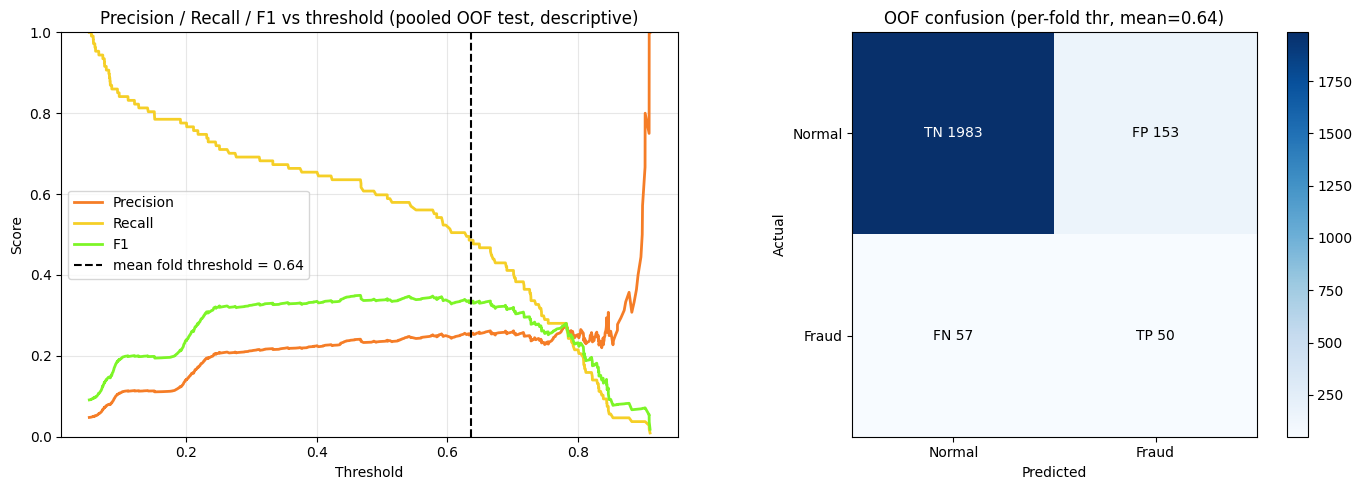

{'cut_level': 1,
 'n_test': 2243,
 'n_fraud_test': 107,
 'roc_auc': 0.8251995169589414,
 'auc_pr': 0.23543457212025756,
 'f1': 0.3225806451612903,
 'precision': 0.24630541871921183,
 'recall': 0.4672897196261682,
 'threshold_mean': 0.6362281143665314}

In [38]:
results = evaluate_nested(
    source_ids, labels_augmented, is_cut, session_deltas, all_cut_positions, label_to_int,
    n_splits=5, n_inner_splits=4, n_seeds=3, n_epochs=20, patience=15, lr=1e-3, weight_decay=1e-2,
    batch_size=32, hidden_dim=32, n_layers=2, dropout=0.0, event_emb_dim=16,
    active_feature_columns=['cumulative_time', 'event_frequency_rank'],
    cut_only_training=True, use_fraud_lift=False, reverse_edges=False, cut_level=CUT_LEVEL,
)
results

## 7. Progressive prefix-length evaluation (LSTM)

Identical to the GINE notebook's Section 7, with the random-truncation trainer building a **LSTM** model. Trains one model on a held-out, session-disjoint split and measures threshold-free detection (PR-AUC) and lift at growing prefix lengths on the test split.  (disjoint sessions, threshold-free metrics).

### Functions

In [39]:
def train_single_model_with_random_truncation(training_sids, training_labels, session_deltas, all_cut_positions,
                                              label_to_int, threshold=0.48, active_feature_columns=None,
                                              logs_grouped=None, imputation_values=None, use_fraud_lift=False,
                                              n_epochs=45, patience=15, lr=1e-3, weight_decay=1e-2,
                                              batch_size=32, hidden_dim=32, n_layers=2, dropout=0.0,
                                              event_emb_dim=16, device=None, seed=42,
                                              min_prefix_at_train=3, cut_level=1):
    """Train one GINE model on randomly-truncated sessions, exposing it to the full prefix-length range."""
    if imputation_values is None:
        imputation_values = {}
    if active_feature_columns is None:
        active_feature_columns = []
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(device)

    fraud_lift_map = None
    if use_fraud_lift:
        fraud_lift_map = compute_fraud_lift_map(cut_level=cut_level, training_session_ids=training_sids,
                                                training_label=training_labels, session_deltas=session_deltas,
                                                all_cut_positions=all_cut_positions)

    labels_bin = [1 if lab == "fraud" else 0 for lab in training_labels]
    n_pos = sum(labels_bin)
    n_neg = len(labels_bin) - n_pos
    pos_weight = torch.tensor([max(n_neg, 1) / max(n_pos, 1)], dtype=torch.float32)

    n_event_types = max(label_to_int.values()) + 2
    n_edge_features = 2 if use_fraud_lift else 1
    n_scalar = len(active_feature_columns)

    torch.manual_seed(seed)
    np.random.seed(seed)
    model = LSTMFraudModel(
        n_event_types=n_event_types, n_scalar_node_features=n_scalar,
        event_emb_dim=event_emb_dim, hidden_dim=hidden_dim, n_layers=n_layers, dropout=dropout,
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    for epoch in range(n_epochs):
        print(f"Epoch: {epoch}/{n_epochs}")
        epoch_data = []
        for sid, lab in zip(training_sids, training_labels):
            cut_position = all_cut_positions[sid].get(1)
            if cut_position is None or cut_position < min_prefix_at_train:
                continue
            truncation = np.random.randint(min_prefix_at_train, cut_position + 1)
            d = session_to_pyg_data(sid, session_deltas, truncation, 1 if lab == "fraud" else 0,
                                    label_to_int, active_feature_columns, logs_grouped, imputation_values,
                                    fraud_lift_map, False)
            if d is not None:
                epoch_data.append(d)
        if not epoch_data:
            continue
        _train_one_epoch(model, DataLoader(epoch_data, batch_size=batch_size, shuffle=True), optimizer, pos_weight, device)

    print(f"Trained for {n_epochs} epochs with random truncation per epoch")
    return model, threshold, fraud_lift_map


def evaluate_at_progressive_prefix_lengths_auc(model, test_sids, test_labels, session_deltas,
                                               label_to_int, active_feature_columns,
                                               logs_grouped=None, imputation_values=None, fraud_lift_map=None,
                                               min_prefix=3, max_prefix=40, device=None):
    """Threshold-independent evaluation: PR AUC and ROC AUC at progressive prefix lengths."""
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(device)
    model = model.to(device)
    model.eval()

    test_labels_bin = [1 if l == "fraud" else 0 for l in test_labels]
    rows = []
    proba_traces = {sid: {} for sid in test_sids}

    for prefix_length in range(min_prefix, max_prefix + 1):
        eligible_data = []
        eligible_labels_bin = []
        eligible_sids = []
        for sid, lab_bin in zip(test_sids, test_labels_bin):
            if len(session_deltas[sid]) < prefix_length:
                continue
            d = session_to_pyg_data(sid, session_deltas, prefix_length, lab_bin, label_to_int,
                                    active_feature_columns, logs_grouped, imputation_values, fraud_lift_map, False)
            if d is not None:
                eligible_data.append(d)
                eligible_labels_bin.append(lab_bin)
                eligible_sids.append(sid)

        if len(eligible_data) < 2 or len(set(eligible_labels_bin)) < 2:
            rows.append({"prefix_length": prefix_length, "n_eligible": len(eligible_data),
                         "n_fraud": sum(eligible_labels_bin), "pr_auc": np.nan, "roc_auc": np.nan})
            continue

        probs = _predict_proba(model, DataLoader(eligible_data, batch_size=32, shuffle=False), device)
        y_true = np.array(eligible_labels_bin)

        for sid, prob in zip(eligible_sids, probs):
            proba_traces[sid][prefix_length] = float(prob)

        rows.append({
            "prefix_length": prefix_length,
            "n_eligible": len(eligible_data),
            "n_fraud": int(y_true.sum()),
            "pr_auc": float(average_precision_score(y_true, probs)),
            "roc_auc": float(roc_auc_score(y_true, probs)),
        })
    return pd.DataFrame(rows), proba_traces


def compute_transaction_position_stats(test_sids, all_cut_positions, max_level=3):
    """Return median/IQR transaction position across test sessions for each level."""
    stats = {}
    for level in range(1, max_level + 1):
        positions = [all_cut_positions[sid][level] for sid in test_sids if level in all_cut_positions[sid]]
        if positions:
            stats[level] = {
                "median": float(np.median(positions)),
                'q25': float(np.percentile(positions, 25)),
                'q75': float(np.percentile(positions, 75)),
                'n': len(positions),
            }
    return stats


def compute_lift(proba_traces, test_sids, test_labels, k_fractions=None, min_prefix=4, max_prefix=40):
    if k_fractions is None:
        k_fractions = [0.01, 0.05, 0.10]

    test_labels_bin = [1 if l == "fraud" else 0 for l in test_labels]
    sid_to_label = dict(zip(test_sids, test_labels_bin))

    rows = []
    for prefix_length in range(min_prefix, max_prefix + 1):
        eligible = [(sid, proba_traces[sid][prefix_length], sid_to_label[sid])
                    for sid in test_sids if prefix_length in proba_traces[sid]]
        if not eligible:
            continue

        total_fraud = sum(1 for _, _, lab in eligible if lab == 1)
        if total_fraud == 0:
            continue

        eligible_sorted = sorted(eligible, key=lambda x: -x[1])
        row = {"prefix_length": prefix_length, "n_total_fraud": total_fraud, "n_eligible": len(eligible)}

        for k_frac in k_fractions:
            top_k_count = max(1, int(np.ceil(len(eligible) * k_frac)))
            top_k_fraud = sum(1 for _, _, lab in eligible_sorted[:top_k_count] if lab == 1)
            baseline_fraud_rate = total_fraud / len(eligible)
            lift = (top_k_fraud / top_k_count) / baseline_fraud_rate if baseline_fraud_rate > 0 else 0
            row[f"lift_top_{int(k_frac * 100)}pct"] = lift
        rows.append(row)

    return pd.DataFrame(rows)


def plot_progressive_detection(df, captured_df=None, transaction_stats=None, save_path=None, topk_df=None):
    """Plot PR AUC or lift vs prefix length with optional transaction markers."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

    if topk_df is None:
        ax1.plot(df["prefix_length"], df["pr_auc"], label="PR AUC", marker=".", linewidth=2)
    else:
        for col in topk_df.columns:
            if col.startswith("lift_top_"):
                pct = col.replace("lift_top_", "").replace("pct", "")
                ax1.plot(topk_df["prefix_length"], topk_df[col], marker='.', linewidth=2,
                         linestyle="--", label=f"Fraud in top {pct}% most suspicious")

    if transaction_stats:
        colors = ["red", "orange", "purple"]
        for level, stats in transaction_stats.items():
            color = colors[(level - 1) % len(colors)]
            ax1.axvline(stats["median"], color=color, linestyle='--', alpha=0.6,
                        label=f"Median position of transaction {level}")

    if topk_df is None:
        ax1.set_ylim(0, 1.0)
        ax1.set_title("Detection performance as session prefix grows")
    else:
        ax1.set_title("Lift as session prefix grows")

    ax1.legend(loc='lower right', fontsize=7)
    ax1.grid(alpha=0.3)

    ax2.fill_between(df["prefix_length"], 0, df['n_eligible'], alpha=0.3, label='Total eligible')
    ax2.fill_between(df["prefix_length"], 0, df['n_fraud'], alpha=0.3, color="red", label='of which Fraud')
    ax2.set_xlabel('number of logs observed')
    ax2.set_ylabel("test sessions")
    ax2.legend(loc="upper right", fontsize=7)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    return fig

### Train (random truncation) + progressive evaluation

In [40]:
all_sids = list(session_deltas.keys())
all_lab = np.array([1 if ses_label[s] == 'fraud' else 0 for s in all_sids])
_tr, _te = next(StratifiedGroupKFold(n_splits=5).split(all_sids, all_lab, groups=all_sids))
train_sids = [all_sids[i] for i in _tr]; train_labels = [ses_label[s] for s in train_sids]
test_sids = [all_sids[i] for i in _te]; test_labels = [ses_label[s] for s in test_sids]
print(f"train={len(train_sids)} (fraud {sum(l == 'fraud' for l in train_labels)}) | "
      f"test={len(test_sids)} (fraud {sum(l == 'fraud' for l in test_labels)})")

prog_model, _, _ = train_single_model_with_random_truncation(
    training_sids=train_sids, training_labels=train_labels, session_deltas=session_deltas,
    all_cut_positions=all_cut_positions, label_to_int=label_to_int,
    active_feature_columns=['cumulative_time', 'event_frequency_rank'],
    n_epochs=20, hidden_dim=32, n_layers=2, dropout=0.0, event_emb_dim=16, seed=42, device='cpu',
)
df_result, proba_traces = evaluate_at_progressive_prefix_lengths_auc(
    prog_model, test_sids, test_labels, session_deltas, label_to_int,
    active_feature_columns=['cumulative_time', 'event_frequency_rank'], min_prefix=4, max_prefix=40, device='cpu',
)
prog_stats = compute_transaction_position_stats(test_sids, all_cut_positions, max_level=1)
topk_df = compute_lift(proba_traces, test_sids, test_labels, k_fractions=[0.01, 0.05, 0.10], min_prefix=4, max_prefix=40)
df_result.head()

train=10470 (fraud 86) | test=2617 (fraud 21)
Epoch: 0/20
Epoch: 1/20
Epoch: 2/20
Epoch: 3/20
Epoch: 4/20
Epoch: 5/20
Epoch: 6/20
Epoch: 7/20
Epoch: 8/20
Epoch: 9/20
Epoch: 10/20
Epoch: 11/20
Epoch: 12/20
Epoch: 13/20
Epoch: 14/20
Epoch: 15/20
Epoch: 16/20
Epoch: 17/20
Epoch: 18/20
Epoch: 19/20
Trained for 20 epochs with random truncation per epoch


,prefix_length,n_eligible,n_fraud,pr_auc,roc_auc
0,4,1937,21,0.032285,0.561562
1,5,1937,21,0.038539,0.525773
2,6,1937,21,0.079754,0.571453
3,7,1561,21,0.074899,0.590136
4,8,1498,21,0.098236,0.590450


### Average-precision-vs-prefix plot

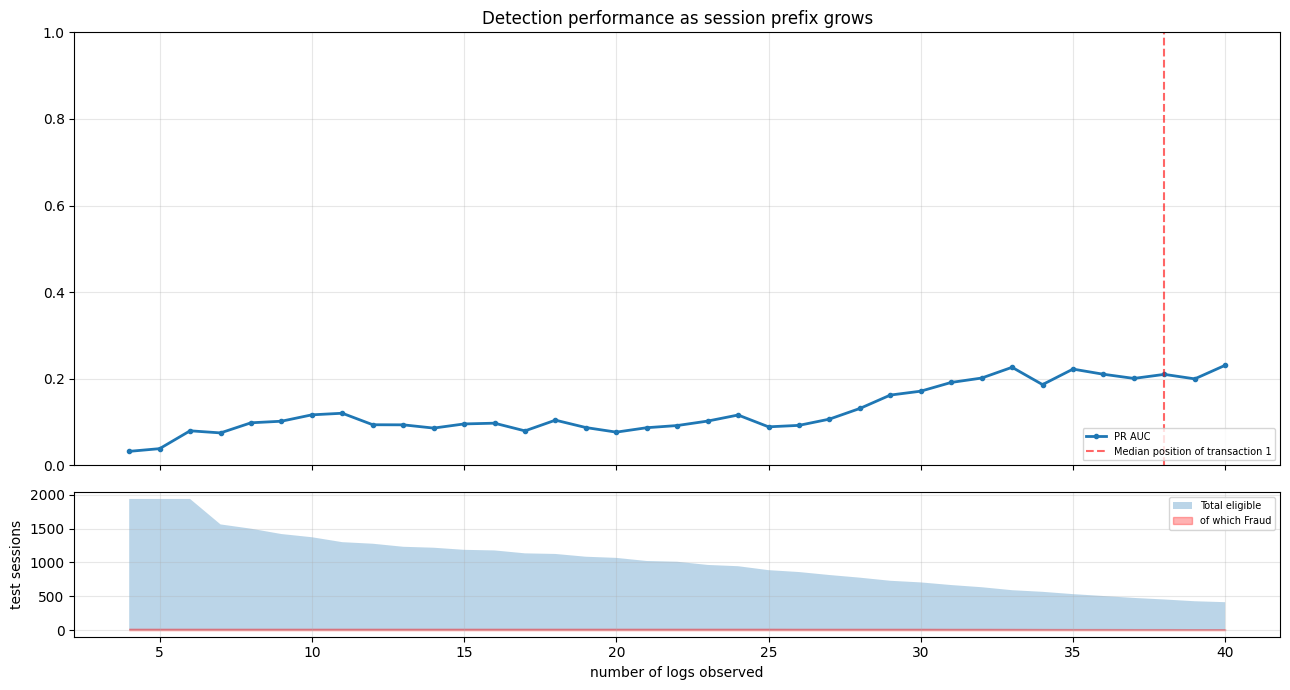

In [41]:
plot_progressive_detection(df_result, transaction_stats=prog_stats)
plt.show()

### Lift-vs-prefix plot

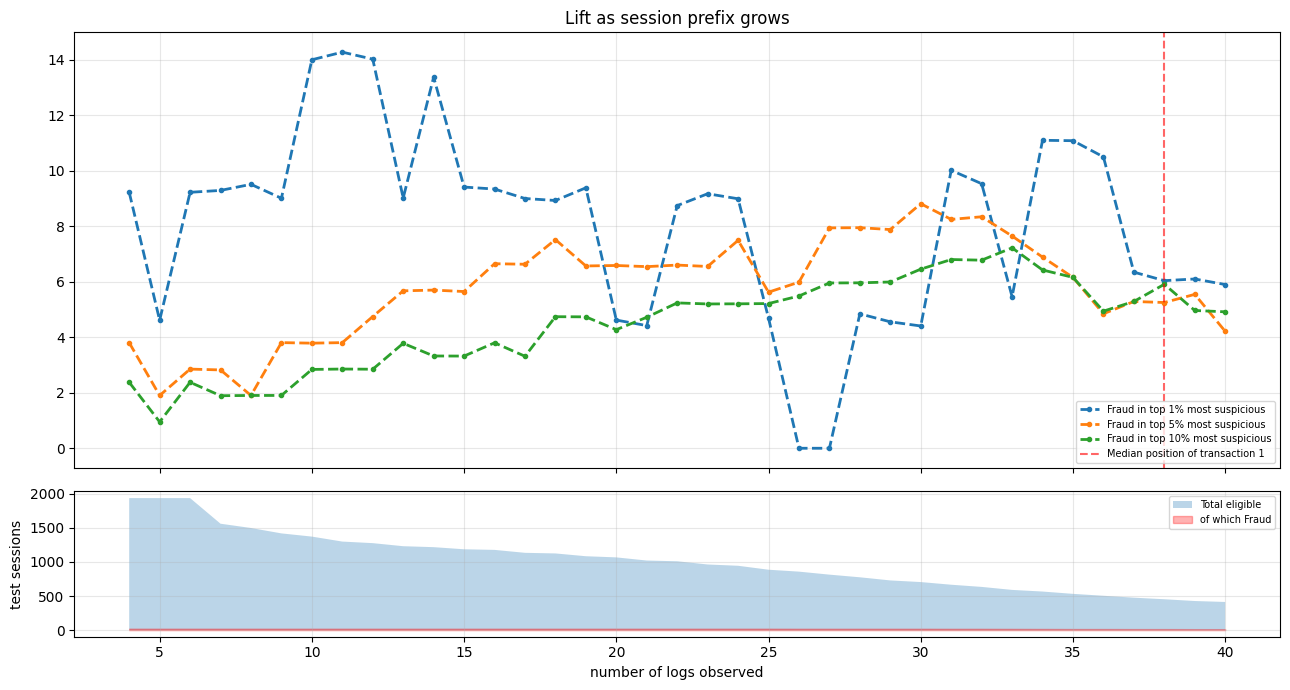

In [42]:
plot_progressive_detection(df_result, topk_df=topk_df, transaction_stats=prog_stats)
plt.show()